# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [107]:
import kagglehub
import pandas as pd
from kagglehub import KaggleDatasetAdapter

file_path = "College.csv"

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "nitishsubandh/dataset",
  file_path,
)

print("First 5 records:", df.head())

Using Colab cache for faster access to the 'dataset' dataset.
First 5 records:   Private  Apps  Accept  Enroll  Top10perc  Top25perc  F.Undergrad  \
0     Yes  1660    1232     721         23         52         2885   
1     Yes  2186    1924     512         16         29         2683   
2     Yes  1428    1097     336         22         50         1036   
3     Yes   417     349     137         60         89          510   
4     Yes   193     146      55         16         44          249   

   P.Undergrad  Outstate  Room.Board  Books  Personal  PhD  Terminal  \
0          537      7440        3300    450      2200   70        78   
1         1227     12280        6450    750      1500   29        30   
2           99     11250        3750    400      1165   53        66   
3           63     12960        5450    450       875   92        97   
4          869      7560        4120    800      1500   76        72   

   S.F.Ratio  perc.alumni  Expend  Grad.Rate  
0       18.1        

## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [108]:
df.shape

(777, 18)

In [109]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 777 entries, 0 to 776
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Private      777 non-null    object 
 1   Apps         777 non-null    int64  
 2   Accept       777 non-null    int64  
 3   Enroll       777 non-null    int64  
 4   Top10perc    777 non-null    int64  
 5   Top25perc    777 non-null    int64  
 6   F.Undergrad  777 non-null    int64  
 7   P.Undergrad  777 non-null    int64  
 8   Outstate     777 non-null    int64  
 9   Room.Board   777 non-null    int64  
 10  Books        777 non-null    int64  
 11  Personal     777 non-null    int64  
 12  PhD          777 non-null    int64  
 13  Terminal     777 non-null    int64  
 14  S.F.Ratio    777 non-null    float64
 15  perc.alumni  777 non-null    int64  
 16  Expend       777 non-null    int64  
 17  Grad.Rate    777 non-null    int64  
dtypes: float64(1), int64(16), object(1)
memory usage: 

In [110]:
df.describe()

,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
count,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.00000
mean,3001.638353,2018.804376,779.972973,27.558559,55.796654,3699.907336,855.298584,10440.669241,4357.526384,549.380952,1340.642214,72.660232,79.702703,14.089704,22.743887,9660.171171,65.46332
std,3870.201484,2451.113971,929.176190,17.640364,19.804778,4850.420531,1522.431887,4023.016484,1096.696416,165.105360,677.071454,16.328155,14.722359,3.958349,12.391801,5221.768440,17.17771
min,81.000000,72.000000,35.000000,1.000000,9.000000,139.000000,1.000000,2340.000000,1780.000000,96.000000,250.000000,8.000000,24.000000,2.500000,0.000000,3186.000000,10.00000
25%,776.000000,604.000000,242.000000,15.000000,41.000000,992.000000,95.000000,7320.000000,3597.000000,470.000000,850.000000,62.000000,71.000000,11.500000,13.000000,6751.000000,53.00000
50%,1558.000000,1110.000000,434.000000,23.000000,54.000000,1707.000000,353.000000,9990.000000,4200.000000,500.000000,1200.000000,75.000000,82.000000,13.600000,21.000000,8377.000000,65.00000
75%,3624.000000,2424.000000,902.000000,35.000000,69.000000,4005.000000,967.000000,12925.000000,5050.000000,600.000000,1700.000000,85.000000,92.000000,16.500000,31.000000,10830.000000,78.00000
max,48094.000000,26330.000000,6392.000000,96.000000,100.000000,31643.000000,21836.000000,21700.000000,8124.000000,2340.000000,6800.000000,103.000000,100.000000,39.800000,64.000000,56233.000000,118.00000


### Duplicadas

In [111]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

## 2. Dados Faltantes

In [112]:
df.isna().sum()

,0
Private,0
Apps,0
Accept,0
Enroll,0
Top10perc,0
Top25perc,0
F.Undergrad,0
P.Undergrad,0
Outstate,0
Room.Board,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*:

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos dois features 'ca'e 'thal'com dados ausentes.

Pela fonte de dados observamos que:

* ca - número de vasos principais coloridos por fluroscopia
* thal - resultados do teste de estresse (talassemia)

*Como os dados foram coletados:*
- O conjunto de dados disponibilizado do UCI é um subconjunto de dados de experimentos publicados em 4 outros conjuntos médicos. Dos 4 conjuntos base para a construção deste dataset, apenas um deles foi utilizado por pesquisadores de Machine Learning anteriormente.

*Qual a natureza da fonte de dados:*
- Considerando que os dados são de pacientes médicos, sabemos que há desafios inerentes a lidar com pessoas nos estudos que podem não ter todos os resultados necessariamente.
- Além disso, o dataset condensa diferentes estudos (Cleveland, Hungary, Switzerland, and the VA Long Beach) de países diferentes, e alguns resultados, como os de *ca* e *thal*, podem ter sido faltantes devido a custos.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [113]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: []
Series([], dtype: float64)


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [114]:
VARS_QUANT = ["Apps", "Accept", "Enroll", "Top10perc", "Top25perc",
              "F.Undergrad", "P.Undergrad", "Outstate", "Room.Board",
              "Books", "Personal", "PhD", "Terminal", "S.F.Ratio",
              "perc.alumni", "Expend", "Grad.Rate"]
VARS_QUALI = ["Private"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Apps,3001.64,1558.00,3870.20,81.00,48094.00,3.72,26.77
Accept,2018.80,1110.00,2451.11,72.00,26330.00,3.42,18.94
Enroll,779.97,434.00,929.18,35.00,6392.00,2.69,8.83
Top10perc,27.56,23.00,17.64,1.00,96.00,1.41,2.21
Top25perc,55.80,54.00,19.80,9.00,100.00,0.26,-0.56
F.Undergrad,3699.91,1707.00,4850.42,139.00,31643.00,2.61,7.70
P.Undergrad,855.30,353.00,1522.43,1.00,21836.00,5.69,55.03
Outstate,10440.67,9990.00,4023.02,2340.00,21700.00,0.51,-0.41
Room.Board,4357.53,4200.00,1096.70,1780.00,8124.00,0.48,-0.19
Books,549.38,500.00,165.11,96.00,2340.00,3.49,28.33


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


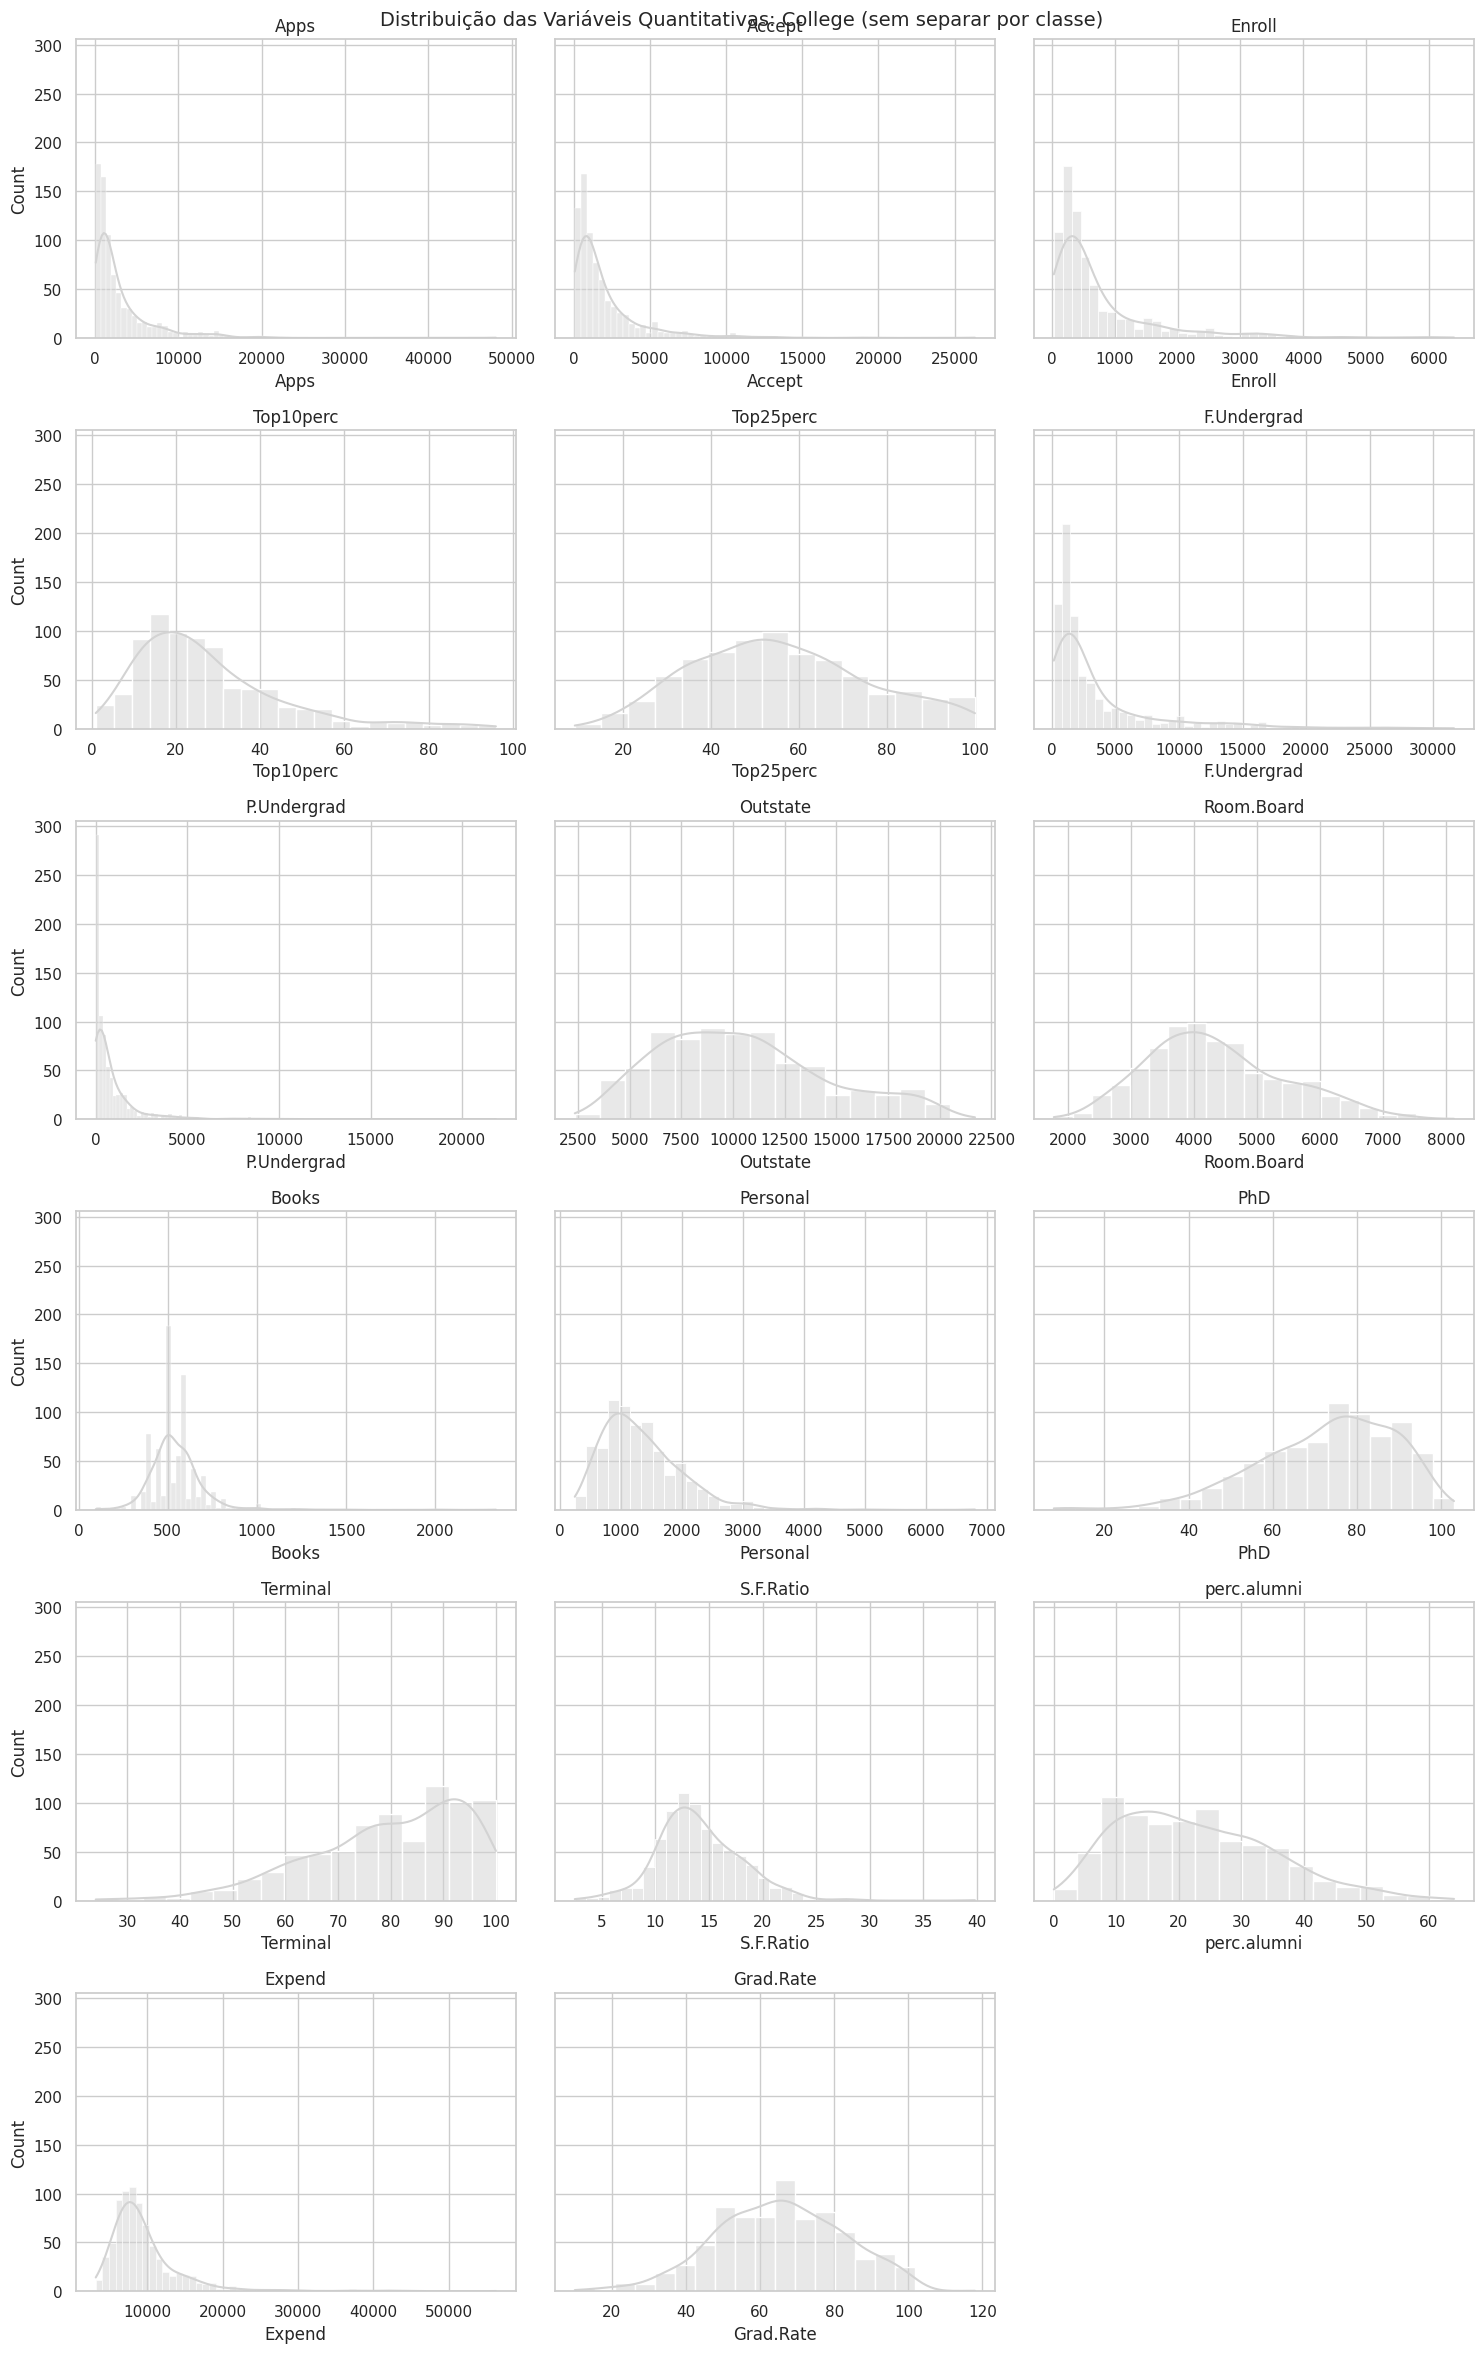

In [67]:
import math

# Calculate the number of rows needed for the subplots
n_cols = 3
n_rows = math.ceil(len(VARS_QUANT) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    if i < len(axes): # Ensure we don't go out of bounds for axes array
        sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
        axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: College (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

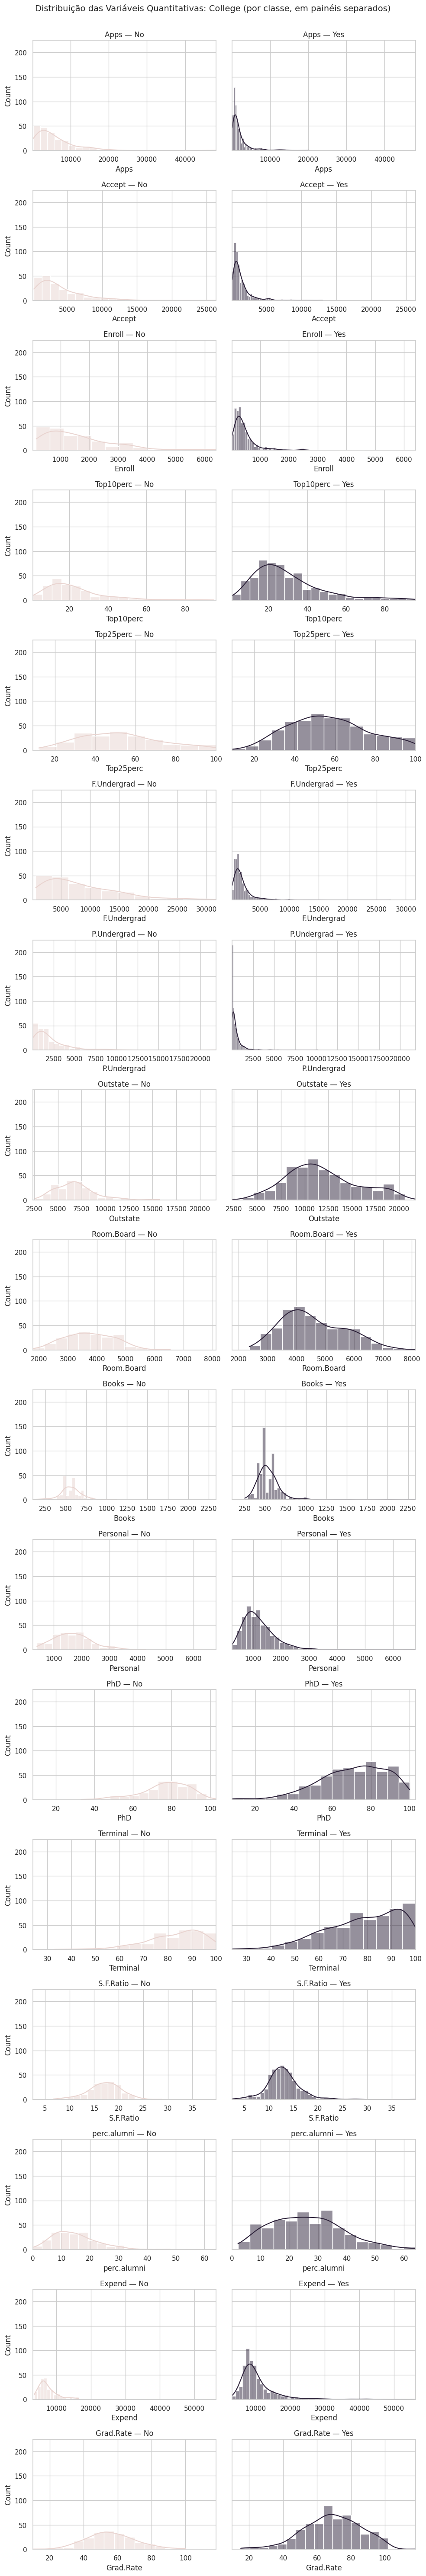

In [68]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("No", COR_CONTEXTO), ("Yes", COR_DESTAQUE)]):
        subset = df[df["Private"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: College (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"?

#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

Shapiro-Wilk — Expend: estatística=0.7108, p-valor=1.643e-34
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


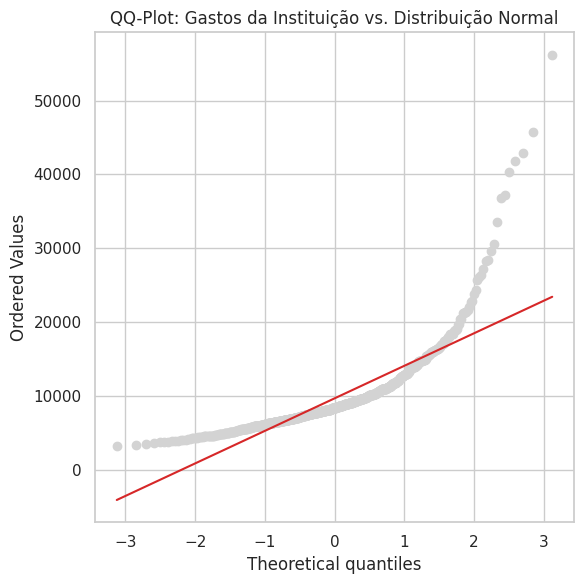

In [69]:
stat_sw, p_valor_sw = stats.shapiro(df["Expend"].dropna())
print(f"Shapiro-Wilk — Expend: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — Expend"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["Expend"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Gastos da Instituição vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [70]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Apps,0.6541,0.000000,True
Accept,0.6642,0.000000,True
Enroll,0.6783,0.000000,True
Top10perc,0.8874,0.000000,True
Top25perc,0.9840,0.000000,True
F.Undergrad,0.6561,0.000000,True
P.Undergrad,0.5231,0.000000,True
Outstate,0.9676,0.000000,True
Room.Board,0.9797,0.000000,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

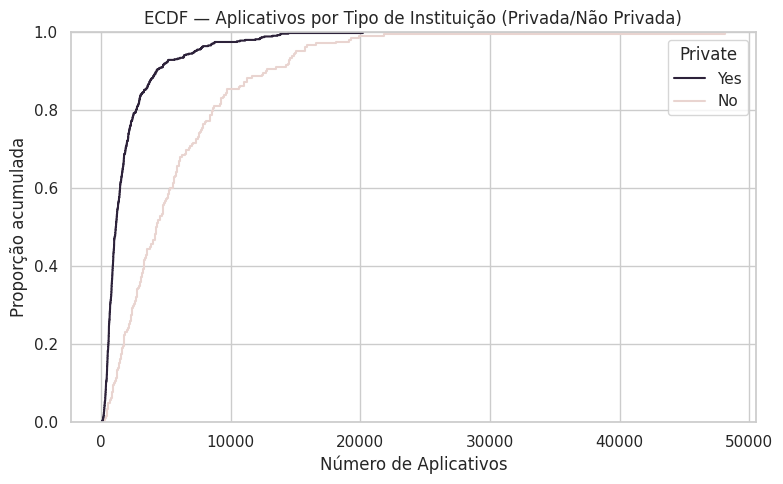

In [71]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="Apps", hue="Private",
             palette={"No": COR_CONTEXTO, "Yes": COR_DESTAQUE})
plt.title("ECDF — Aplicativos por Tipo de Instituição (Privada/Não Privada)")
plt.xlabel("Número de Aplicativos")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

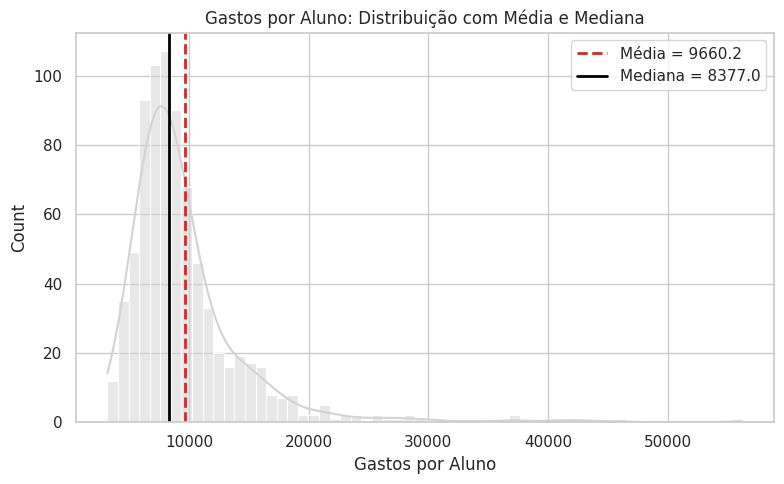

In [72]:
media_expend = df["Expend"].mean()
mediana_expend = df["Expend"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Expend", kde=True, color=COR_NEUTRA)
plt.axvline(media_expend, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_expend:.1f}")
plt.axvline(mediana_expend, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_expend:.1f}")
plt.title("Gastos por Aluno: Distribuição com Média e Mediana")
plt.xlabel("Gastos por Aluno")
plt.legend()
plt.tight_layout()
plt.show()

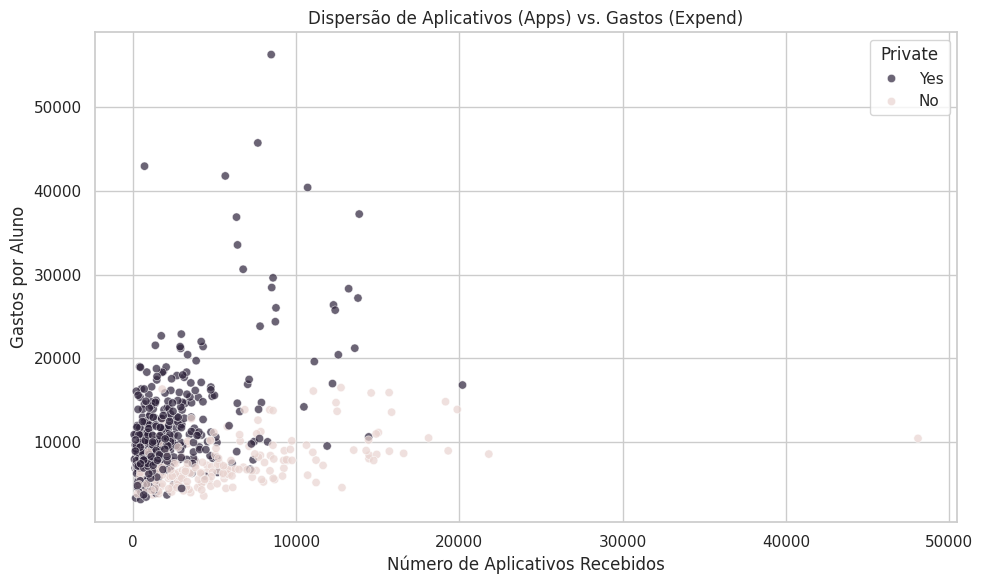

In [73]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Apps", y="Expend", hue="Private",
                palette={"No": COR_CONTEXTO, "Yes": COR_DESTAQUE}, alpha=0.7)
plt.title("Dispersão de Aplicativos (Apps) vs. Gastos (Expend)")
plt.xlabel("Número de Aplicativos Recebidos")
plt.ylabel("Gastos por Aluno")
plt.tight_layout()
plt.show()

### Dispersão

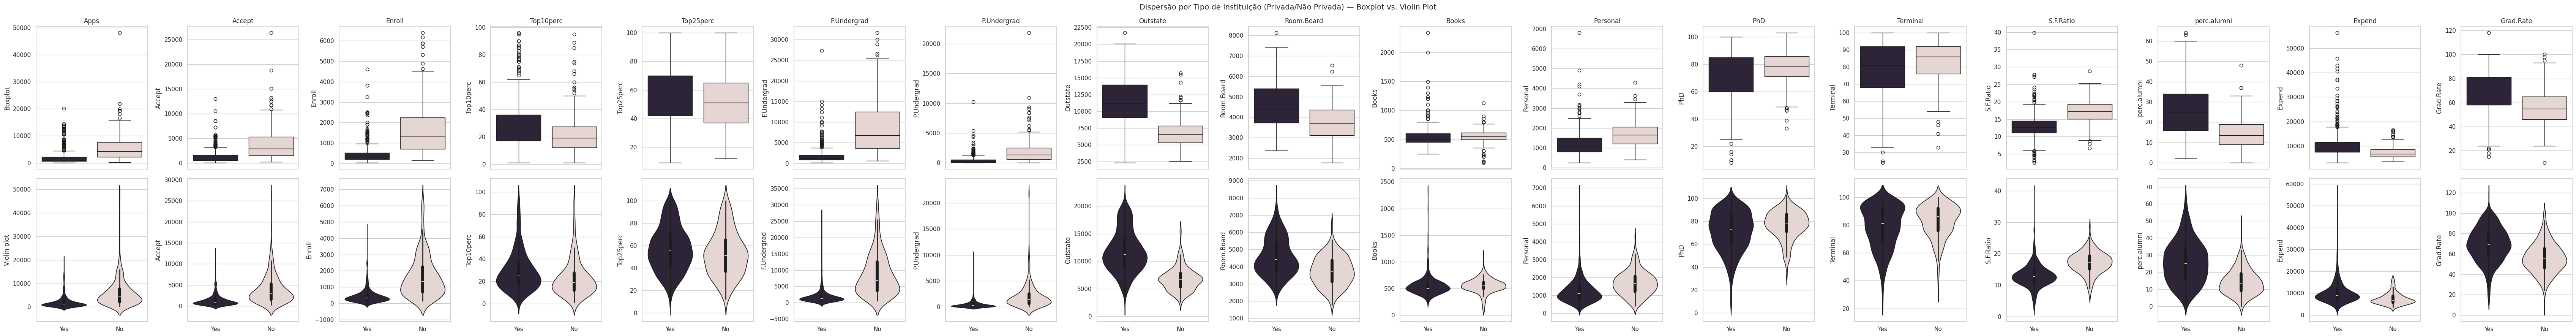

In [74]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"No": COR_CONTEXTO, "Yes": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="Private", y=col, hue="Private",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="Private", y=col, hue="Private",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Tipo de Instituição (Privada/Não Privada) — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [75]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
Apps,-3496.0,7896.0,70.0
Accept,-2126.0,5154.0,73.0
Enroll,-748.0,1892.0,79.0
Top10perc,-15.0,65.0,39.0
Top25perc,-1.0,111.0,0.0
F.Undergrad,-3527.5,8524.5,97.0
P.Undergrad,-1213.0,2275.0,67.0
Outstate,-1087.5,21332.5,1.0
Room.Board,1417.5,7229.5,7.0
Books,275.0,795.0,46.0


### Visualizando os Outliers

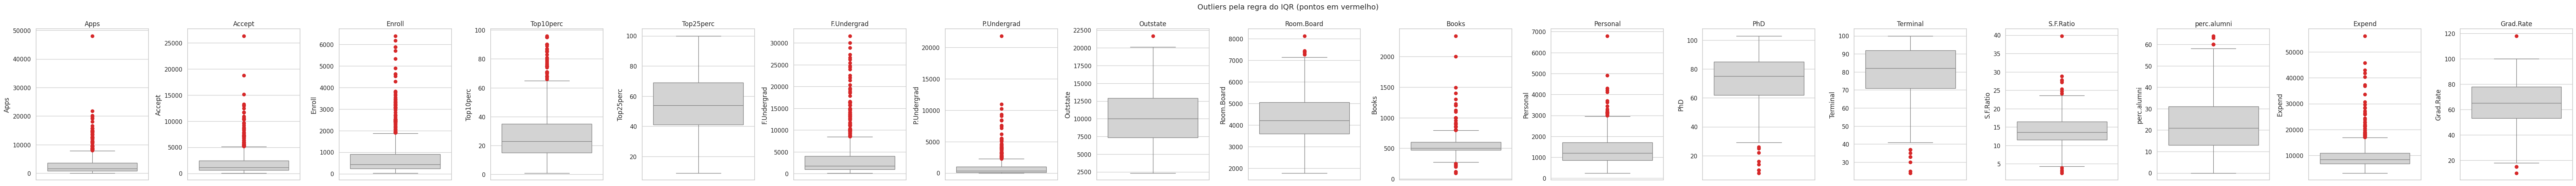

In [76]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

In [77]:
linhas_antes = df.shape[0]
df_antes = df.copy()
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 777 | Linhas depois: 777 | Removidas: 0


In [78]:
corr_apps_expend = df[['Apps', 'Expend']].corr()
display(corr_apps_expend)

,Apps,Expend
Apps,1.000000,0.259592
Expend,0.259592,1.000000


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

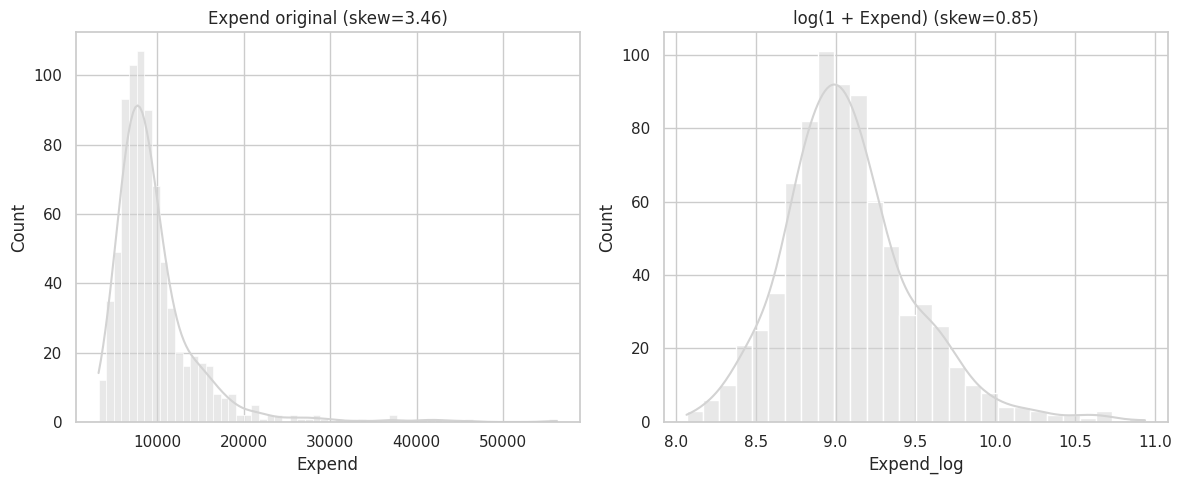

In [79]:
df["Expend_log"] = np.log1p(df["Expend"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="Expend", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Expend original (skew={df['Expend'].skew():.2f})")

sns.histplot(data=df, x="Expend_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Expend) (skew={df['Expend_log'].skew():.2f})")

plt.tight_layout()
plt.show()

In [80]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")
print(corr_spearman['Apps'])

Apps           1.000000
Accept         0.979390
Enroll         0.926169
Top10perc      0.306458
Top25perc      0.382820
F.Undergrad    0.884835
P.Undergrad    0.396983
Outstate       0.049398
Room.Board     0.191132
Books          0.231727
Personal       0.194276
PhD            0.537007
Terminal       0.497970
S.F.Ratio      0.212016
perc.alumni   -0.082698
Expend         0.194623
Grad.Rate      0.193279
Name: Apps, dtype: float64


**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [115]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Apps,3001.64,1558.00,3870.20,81.00,48094.00,3.72,26.77
Accept,2018.80,1110.00,2451.11,72.00,26330.00,3.42,18.94
Enroll,779.97,434.00,929.18,35.00,6392.00,2.69,8.83
Top10perc,27.56,23.00,17.64,1.00,96.00,1.41,2.21
Top25perc,55.80,54.00,19.80,9.00,100.00,0.26,-0.56
F.Undergrad,3699.91,1707.00,4850.42,139.00,31643.00,2.61,7.70
P.Undergrad,855.30,353.00,1522.43,1.00,21836.00,5.69,55.03
Outstate,10440.67,9990.00,4023.02,2340.00,21700.00,0.51,-0.41
Room.Board,4357.53,4200.00,1096.70,1780.00,8124.00,0.48,-0.19
Books,549.38,500.00,165.11,96.00,2340.00,3.49,28.33


### Comparando "antes"x "depois""



In [82]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
Apps,3.724,3.724,26.774,26.774,0.0,0.0
Accept,3.418,3.418,18.938,18.938,0.0,0.0
Enroll,2.690,2.690,8.832,8.832,0.0,0.0
Top10perc,1.413,1.413,2.208,2.208,0.0,0.0
Top25perc,0.259,0.259,-0.564,-0.564,0.0,0.0
F.Undergrad,2.610,2.610,7.697,7.697,0.0,0.0
P.Undergrad,5.692,5.692,55.035,55.035,0.0,0.0
Outstate,0.509,0.509,-0.414,-0.414,0.0,0.0
Room.Board,0.477,0.477,-0.188,-0.188,0.0,0.0
Books,3.485,3.485,28.333,28.333,0.0,0.0


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [83]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["Expend"].dropna())
print(f"Shapiro-Wilk (antes)  — Expend: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g})")
print(f"Shapiro-Wilk (depois) — Expend: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — Expend: estatística=0.7108, p-valor=1.643e-34)
Shapiro-Wilk (depois) — Expend: estatística=0.7108, p-valor=1.643e-34


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

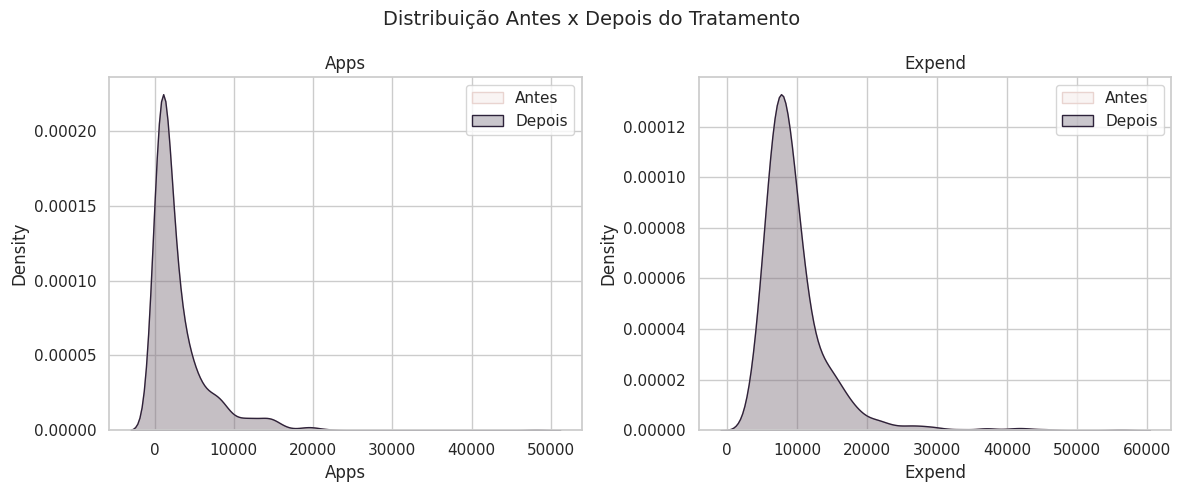

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["Apps", "Expend"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [85]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- Private ---
         absoluta  relativa
Private                    
Yes           565     0.727
No            212     0.273


#### Visualizando as frequências

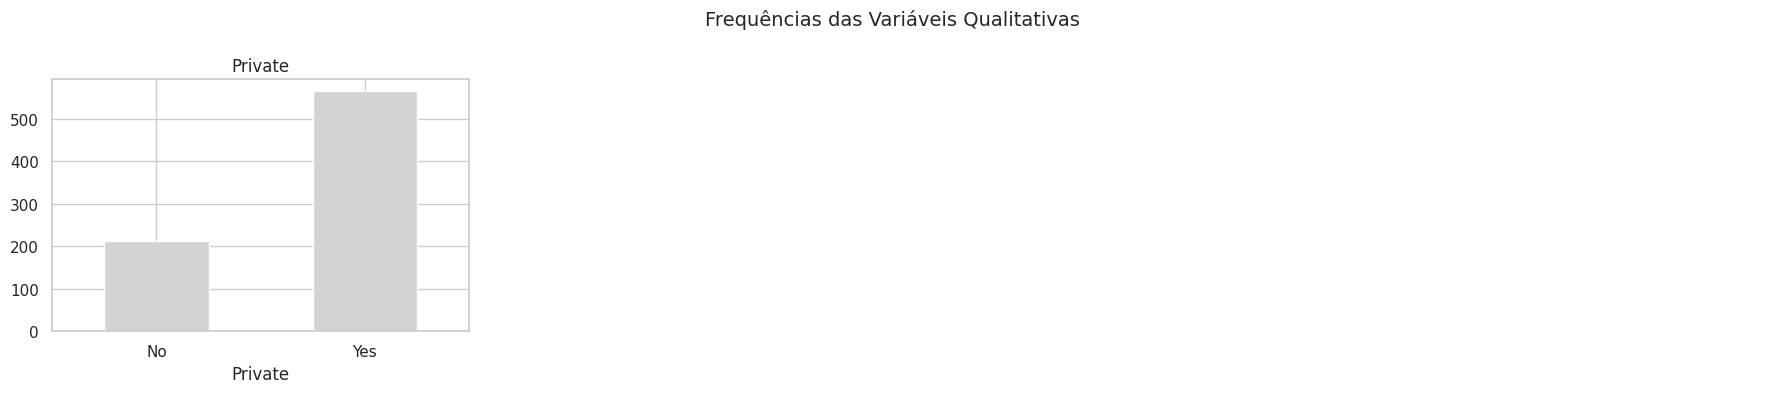

In [86]:
import math

# Lista local de variáveis qualitativas para este plot. Adicione mais nomes de colunas qualitativas aqui.
qualitative_variables_to_plot = ["Private"]
# Exemplo: qualitative_variables_to_plot = ["Private", "Nome_da_Sua_Variavel_Qualitativa", "Outra_Variavel_Categorica"]

n_vars = len(qualitative_variables_to_plot)
n_cols = 4  # Mantém 4 colunas por linha
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4.5, n_rows * 4), sharey=True)
axes = axes.ravel() # Achata o array de eixos para facilitar a iteração

for i, col in enumerate(qualitative_variables_to_plot):
    if i < len(axes): # Garante que não tentamos plotar em um eixo que não existe
        df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
        axes[i].set_title(col)
        axes[i].tick_params(axis="x", rotation=0)

# Desliga os eixos extras se houver mais subplots do que variáveis
for j in range(n_vars, len(axes)):
    axes[j].axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

### Comparando Quantitativas por Tipo de Instituição

Vamos visualizar as médias de algumas variáveis quantitativas, como candidaturas, aceitações, matrículas, gastos e taxa de graduação, separadas por tipo de instituição (Privada/Não Privada). Isso nos dará uma visão rápida das diferenças entre os dois grupos.

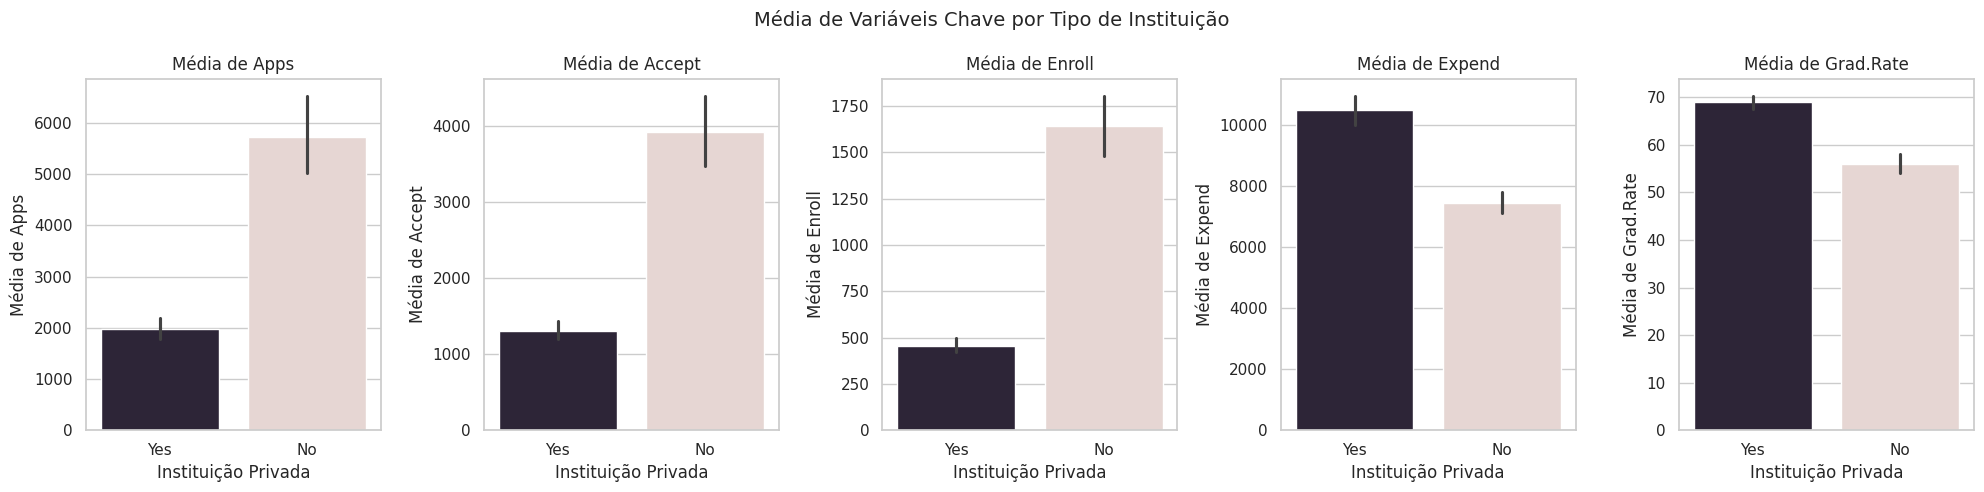

In [87]:
variables_to_compare = ['Apps', 'Accept', 'Enroll', 'Expend', 'Grad.Rate']

fig, axes = plt.subplots(1, len(variables_to_compare), figsize=(4 * len(variables_to_compare), 5))

for i, col in enumerate(variables_to_compare):
    sns.barplot(data=df, x='Private', y=col, hue='Private',
                palette={'No': COR_CONTEXTO, 'Yes': COR_DESTAQUE}, legend=False, ax=axes[i])
    axes[i].set_title(f'Média de {col}')
    axes[i].set_xlabel('Instituição Privada')
    axes[i].set_ylabel(f'Média de {col}')
    axes[i].tick_params(axis='x', rotation=0)

fig.suptitle('Média de Variáveis Chave por Tipo de Instituição', fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [88]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
Private,2.0,2.67,0.846


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

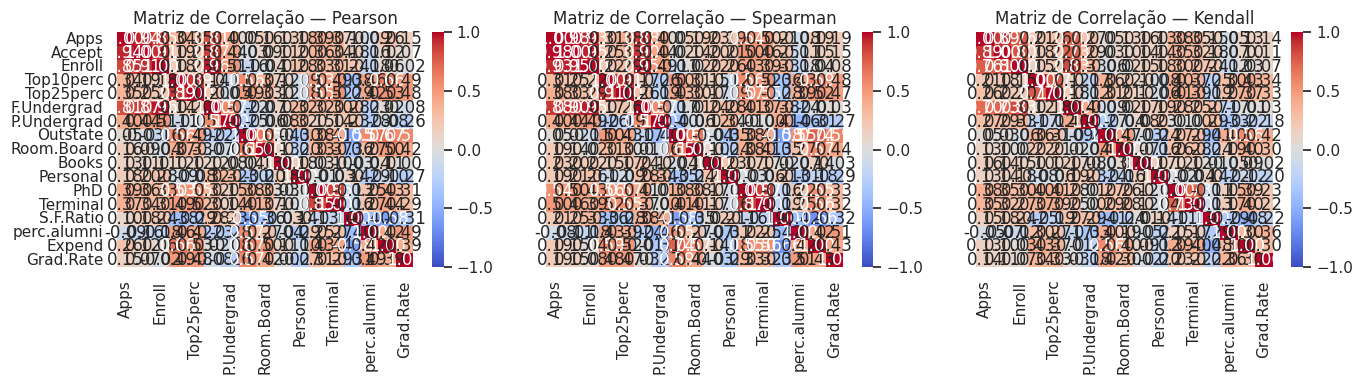

In [89]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

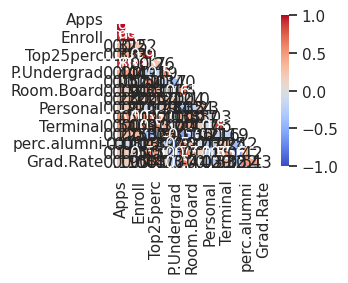

In [90]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

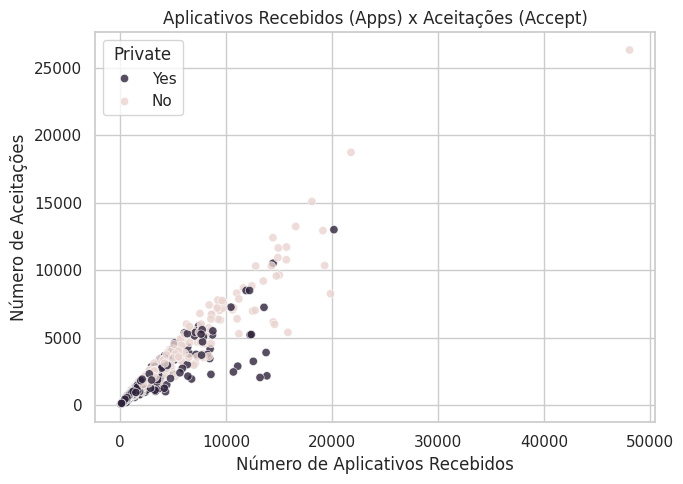

In [91]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Apps", y="Accept", hue="Private",
                palette={"No": COR_CONTEXTO, "Yes": COR_DESTAQUE}, alpha=0.8)
plt.title("Aplicativos Recebidos (Apps) x Aceitações (Accept)")
plt.xlabel("Número de Aplicativos Recebidos")
plt.ylabel("Número de Aceitações")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme a idade aumenta, `thalach` tende a cair)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [92]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_no = df.loc[df["Private"] == "No", col]
    grupo_yes = df.loc[df["Private"] == "Yes", col]

    stat_t, p_t = stats.ttest_ind(grupo_no, grupo_yes, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_no, grupo_yes)                # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
Apps,0.00000,0.00000,True
Accept,0.00000,0.00000,True
Enroll,0.00000,0.00000,True
Top10perc,0.00000,0.00000,True
Top25perc,0.00846,0.00653,True
F.Undergrad,0.00000,0.00000,True
P.Undergrad,0.00000,0.00000,True
Outstate,0.00000,0.00000,True
Room.Board,0.00000,0.00000,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`cp` (tipo de dor no peito) tem 4 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

ANOVA          — Apps entre categorias de Private: estatística=177.915, p-valor=1.0968e-36
Kruskal-Wallis — Apps entre categorias de Private: estatística=172.784, p-valor=1.8245e-39


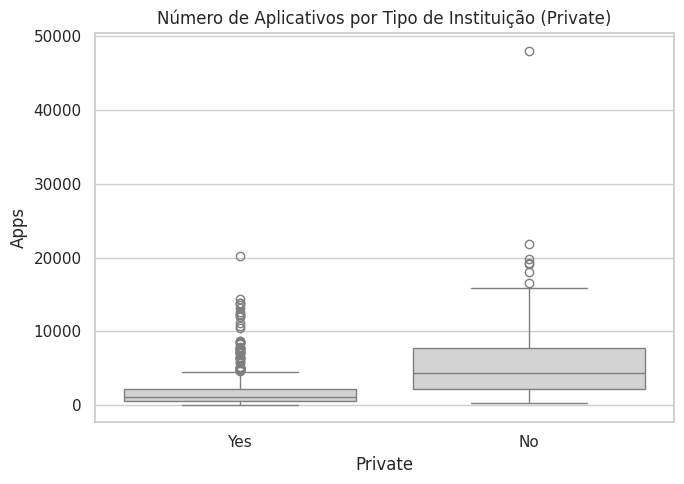

In [93]:
grupos_private = [grupo["Apps"].values for _, grupo in df.groupby("Private")]

stat_anova, p_anova = stats.f_oneway(*grupos_private)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_private)          # não-paramétrico

print(f"ANOVA          — Apps entre categorias de Private: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — Apps entre categorias de Private: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Private", y="Apps", color=COR_NEUTRA)
plt.title("Número de Aplicativos por Tipo de Instituição (Private)")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `cp`? Como já sabemos que `thalach` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

#### Quantitativa x Qualitativa

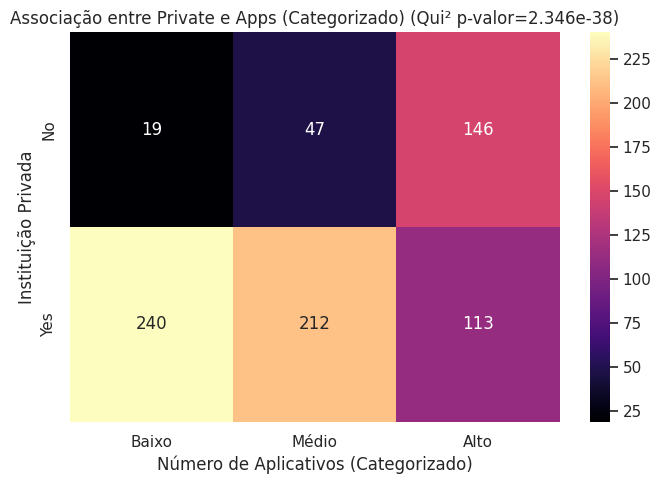

In [94]:
df['Apps_binned'] = pd.qcut(df['Apps'], q=3, labels=['Baixo', 'Médio', 'Alto'], duplicates='drop')

contingencia_private_apps = pd.crosstab(df['Private'], df['Apps_binned'])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_private_apps)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(contingencia_private_apps, annot=True, fmt='d', cmap='magma', ax=ax)
ax.set_title(f'Associação entre Private e Apps (Categorizado) (Qui² p-valor={p_chi2:.4g})')
plt.xlabel('Número de Aplicativos (Categorizado)')
plt.ylabel('Instituição Privada')
plt.tight_layout()
plt.show()

from scipy import stats

# ajuste essa lista com as colunas quantitativas do seu College.csv
VARS_QUANT = ["Apps", "Accept", "Enroll", "Top10perc", "Top25perc",
              "F.Undergrad", "P.Undergrad", "Outstate", "Room.Board",
              "Books", "Personal", "PhD", "Terminal", "S.F.Ratio",
              "perc.alumni", "Expend", "Grad.Rate"]

resultados_comparacao = []
for col in VARS_QUANT:
    grupo_no = df.loc[df["Private"] == "No", col]
    grupo_yes = df.loc[df["Private"] == "Yes", col]

    stat_t, p_t = stats.ttest_ind(grupo_no, grupo_yes, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_no, grupo_yes)                # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("vari

**Pra discutir:** o p-valor do Qui-Quadrado indica que `thal` e `doenca_cardiaca` são independentes, ou há associação estatisticamente significativa entre elas?

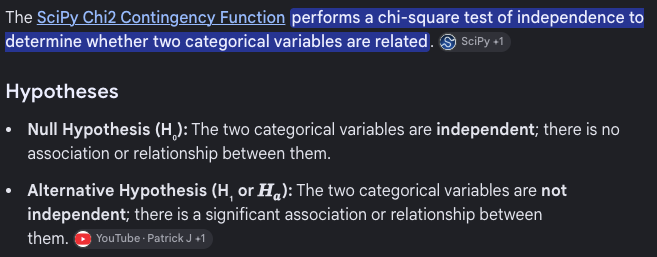

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [95]:
print("Desbalanceamento — Private:")
print(metrica_desbalanceamento(df["Private"]))

Desbalanceamento — Private:
n_classes                 2.000
razao_desbalanceamento    2.670
entropia_normalizada      0.846
dtype: float64


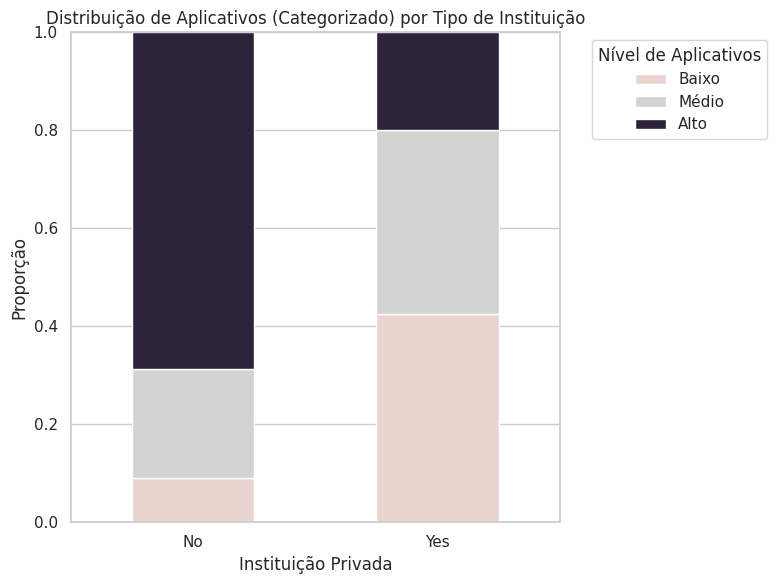

In [96]:
proporcoes_apps_por_private = pd.crosstab(df["Private"], df["Apps_binned"], normalize="index").round(3)

fig, ax = plt.subplots(figsize=(8, 6))

proporcoes_apps_por_private.plot(kind="bar", stacked=True, ax=ax,
                                   color=[COR_CONTEXTO, COR_NEUTRA, COR_DESTAQUE]) # Atribuir cores distintas
ax.set_title("Distribuição de Aplicativos (Categorizado) por Tipo de Instituição")
ax.set_xlabel("Instituição Privada")
ax.set_ylabel("Proporção")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Nível de Aplicativos", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de diagnóstico positivo varia bastante entre sexo ou faixa etária? Isso pode refletir um padrão clínico real e bem documentado (ex: risco cardíaco cresce com a idade), ou pode ser um artefato de **quem** foi encaminhado para o exame nesses hospitais específicos? A pergunta "a distribuição do desfecho é uniforme entre grupos protegidos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

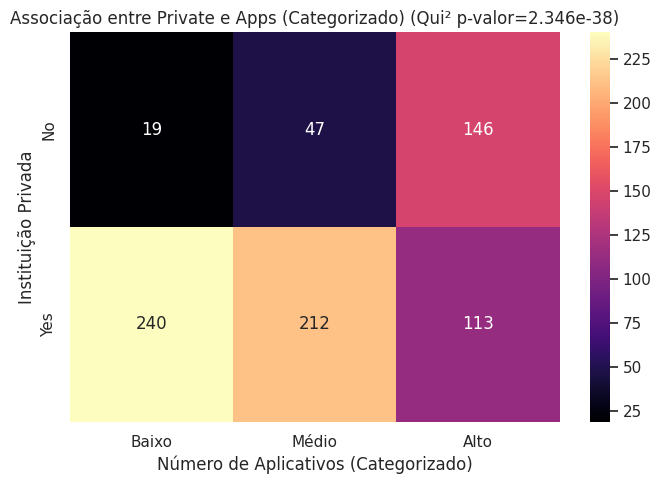

In [97]:
contingencia = pd.crosstab(df["Private"], df["Apps_binned"])
chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Associação entre Private e Apps (Categorizado) (Qui² p-valor={p_valor:.4g})")
plt.xlabel("Número de Aplicativos (Categorizado)")
plt.ylabel("Instituição Privada")
plt.tight_layout()
plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de risco real (idade), pode ser um viés de quem foi encaminhado ao exame (possivelmente sexo), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

#### Outliers bivariados

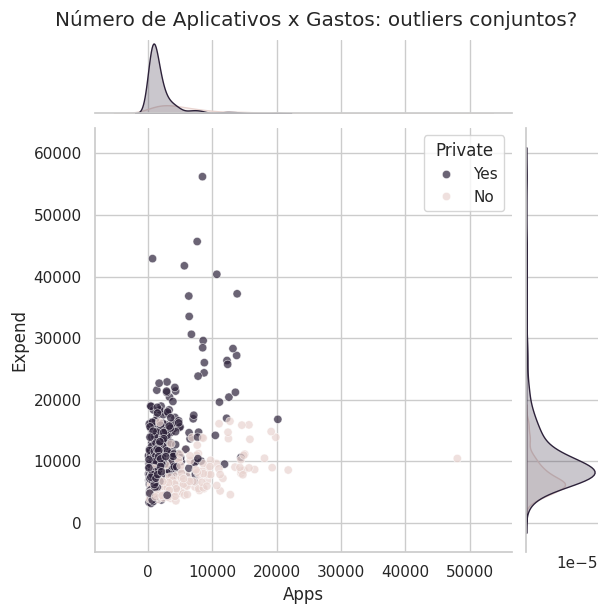

In [98]:
sns.jointplot(data=df, x="Apps", y="Expend", hue="Private",
              palette={"No": COR_CONTEXTO, "Yes": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Número de Aplicativos x Gastos: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `trestbps` e `chol`?

#### Análise Multivariada

##### Matriz de Correlação

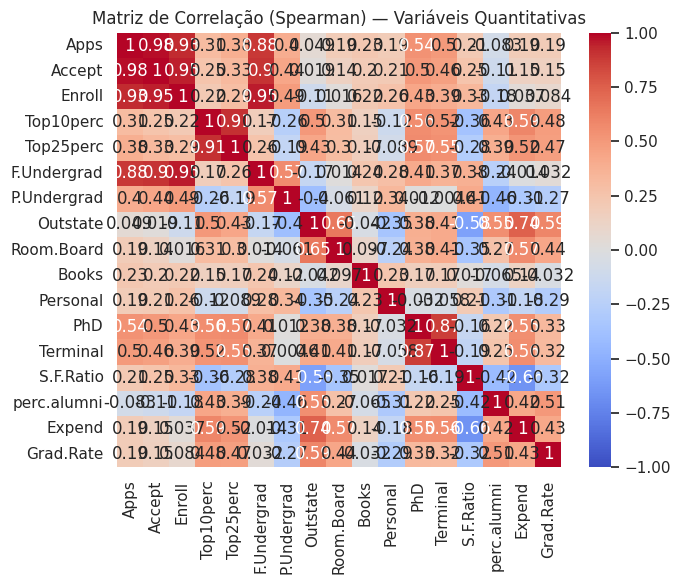

In [99]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

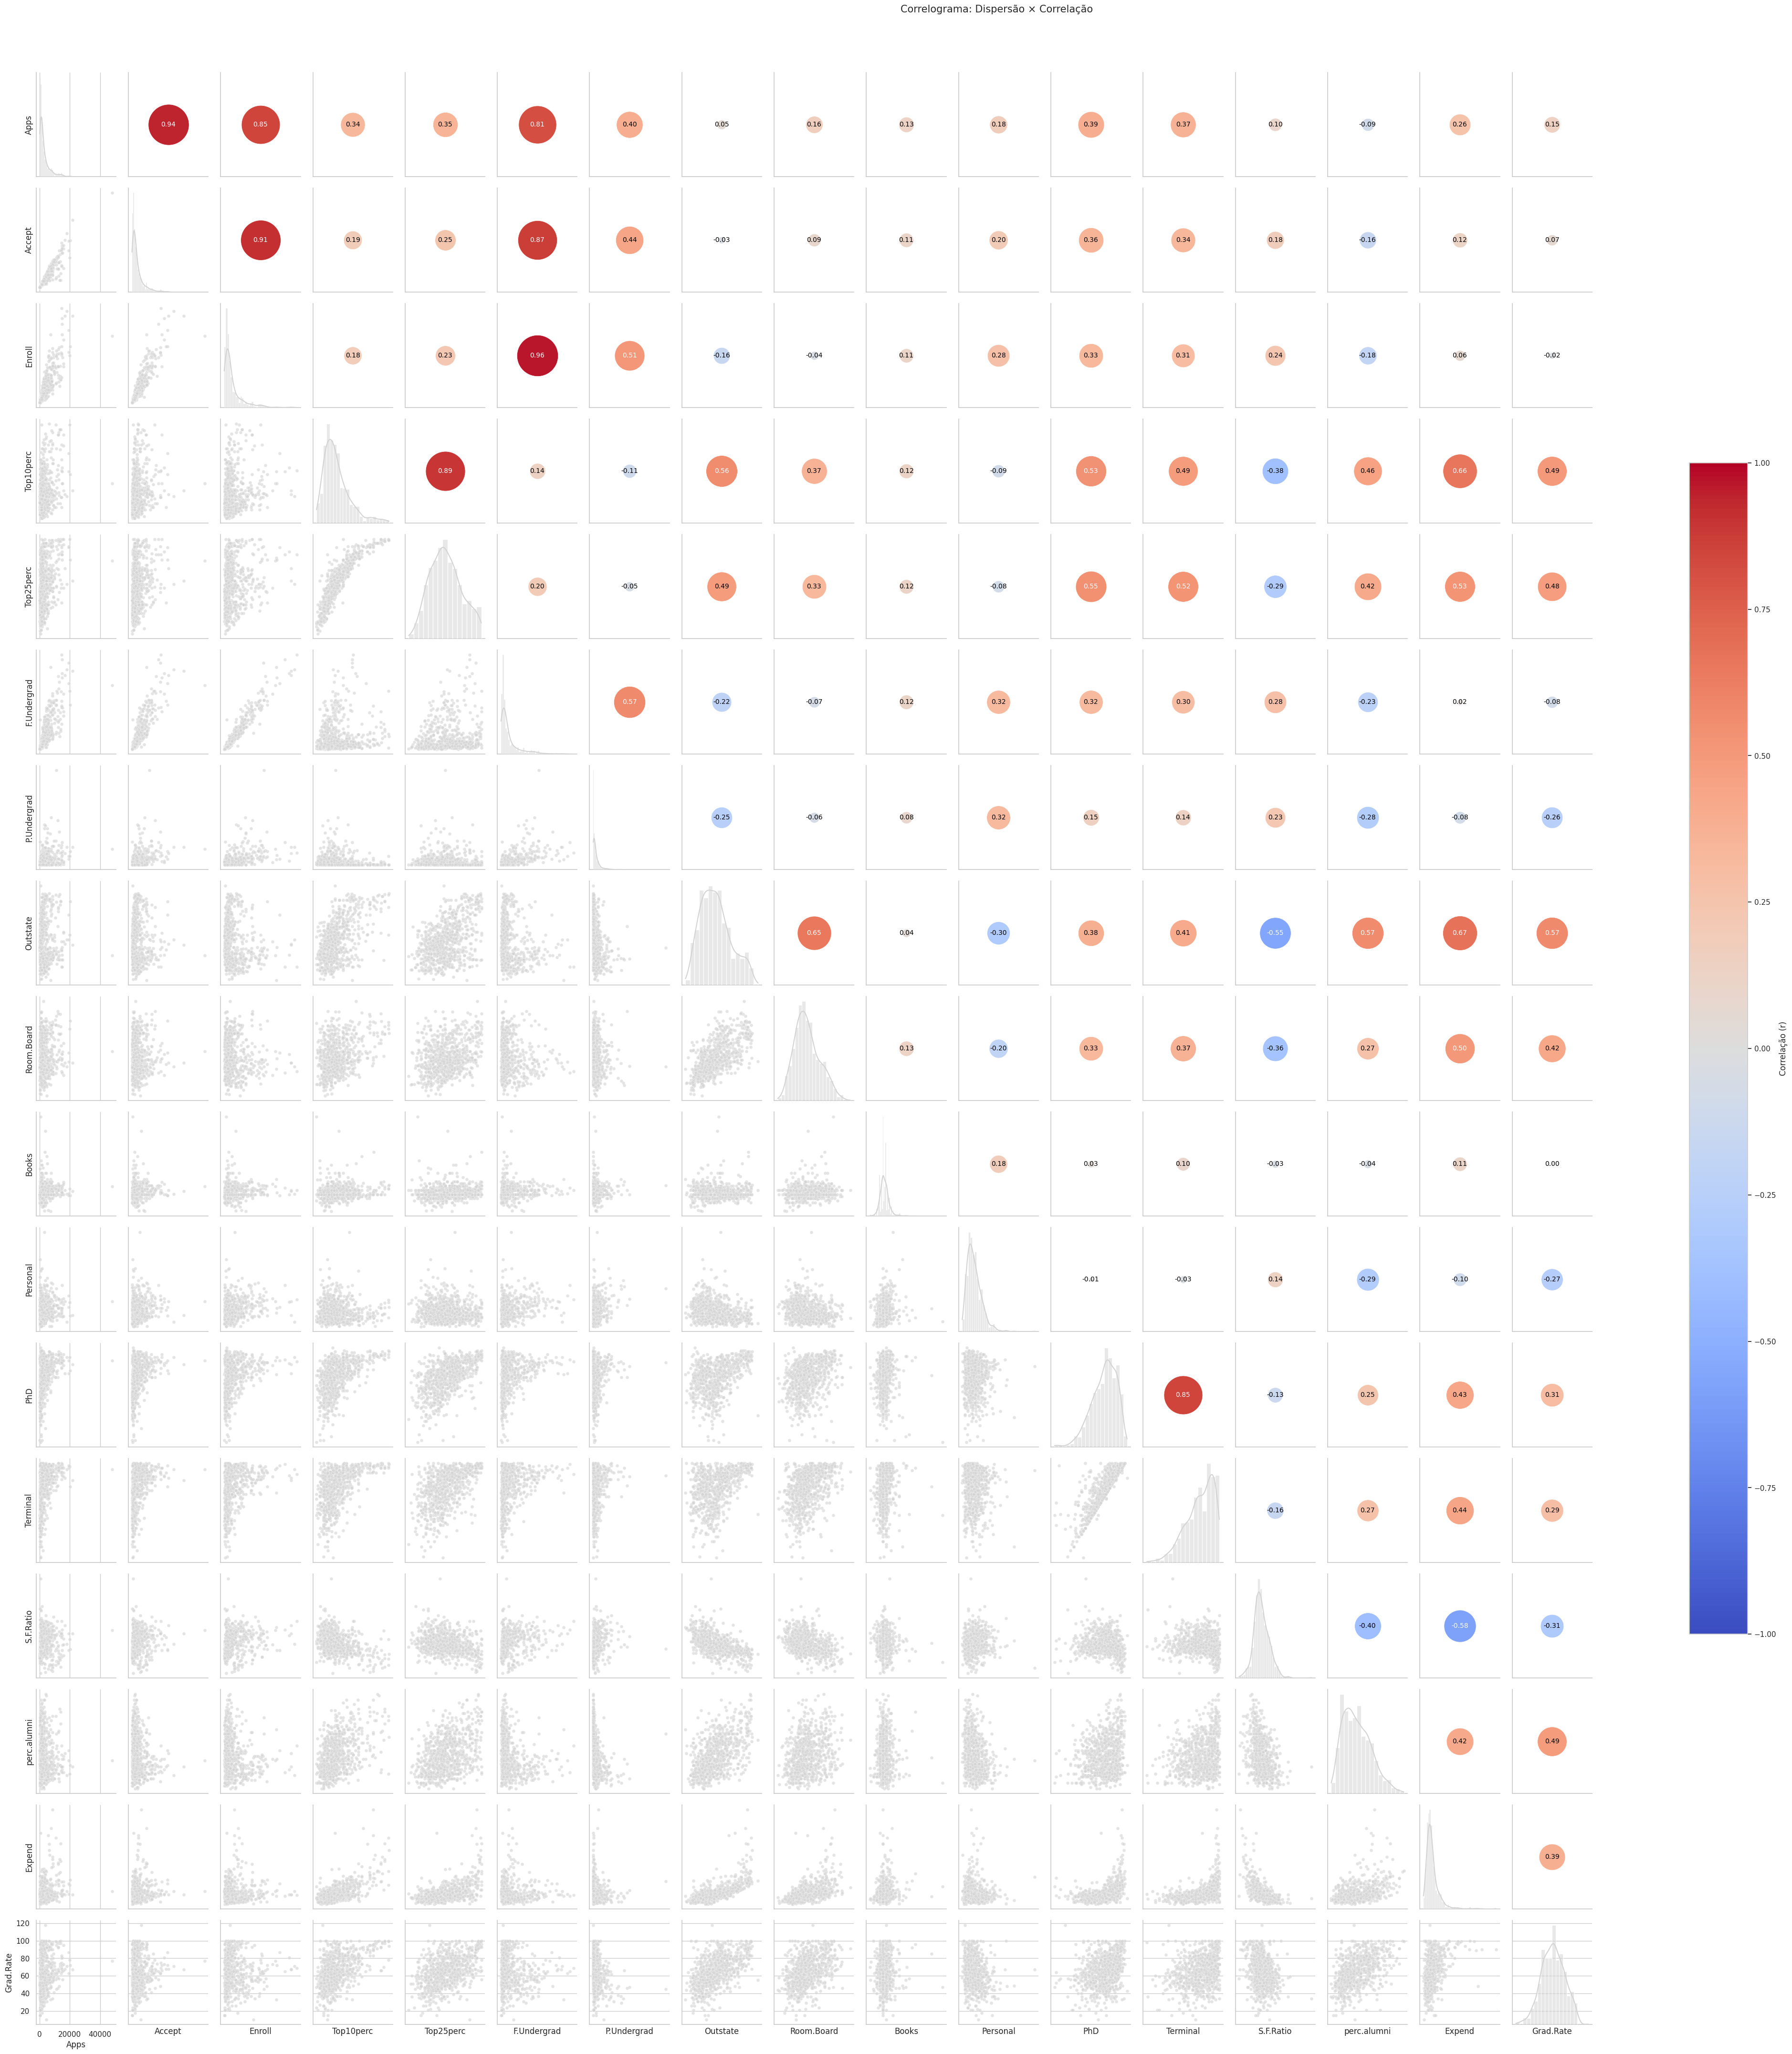

In [100]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




In [101]:
from scipy import stats

# ajuste essa lista com as colunas quantitativas do seu College.csv
VARS_QUANT = ["Apps", "Accept", "Enroll", "Top10perc", "Top25perc",
              "F.Undergrad", "P.Undergrad", "Outstate", "Room.Board",
              "Books", "Personal", "PhD", "Terminal", "S.F.Ratio",
              "perc.alumni", "Expend", "Grad.Rate"]

resultados_comparacao = []
for col in VARS_QUANT:
    grupo_no = df.loc[df["Private"] == "No", col]
    grupo_yes = df.loc[df["Private"] == "Yes", col]

    stat_t, p_t = stats.ttest_ind(grupo_no, grupo_yes, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_no, grupo_yes)                # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
Apps,0.00000,0.00000,True
Accept,0.00000,0.00000,True
Enroll,0.00000,0.00000,True
Top10perc,0.00000,0.00000,True
Top25perc,0.00846,0.00653,True
F.Undergrad,0.00000,0.00000,True
P.Undergrad,0.00000,0.00000,True
Outstate,0.00000,0.00000,True
Room.Board,0.00000,0.00000,True


In [102]:
df["Apps"].kurtosis()

np.float64(26.77425315804892)

In [103]:
pd.DataFrame({
    "assimetria": df[VARS_QUANT].skew().round(3),
    "curtose": df[VARS_QUANT].kurtosis().round(3),
})

,assimetria,curtose
Apps,3.724,26.774
Accept,3.418,18.938
Enroll,2.690,8.832
Top10perc,1.413,2.208
Top25perc,0.259,-0.564
F.Undergrad,2.610,7.697
P.Undergrad,5.692,55.035
Outstate,0.509,-0.414
Room.Board,0.477,-0.188
Books,3.485,28.333


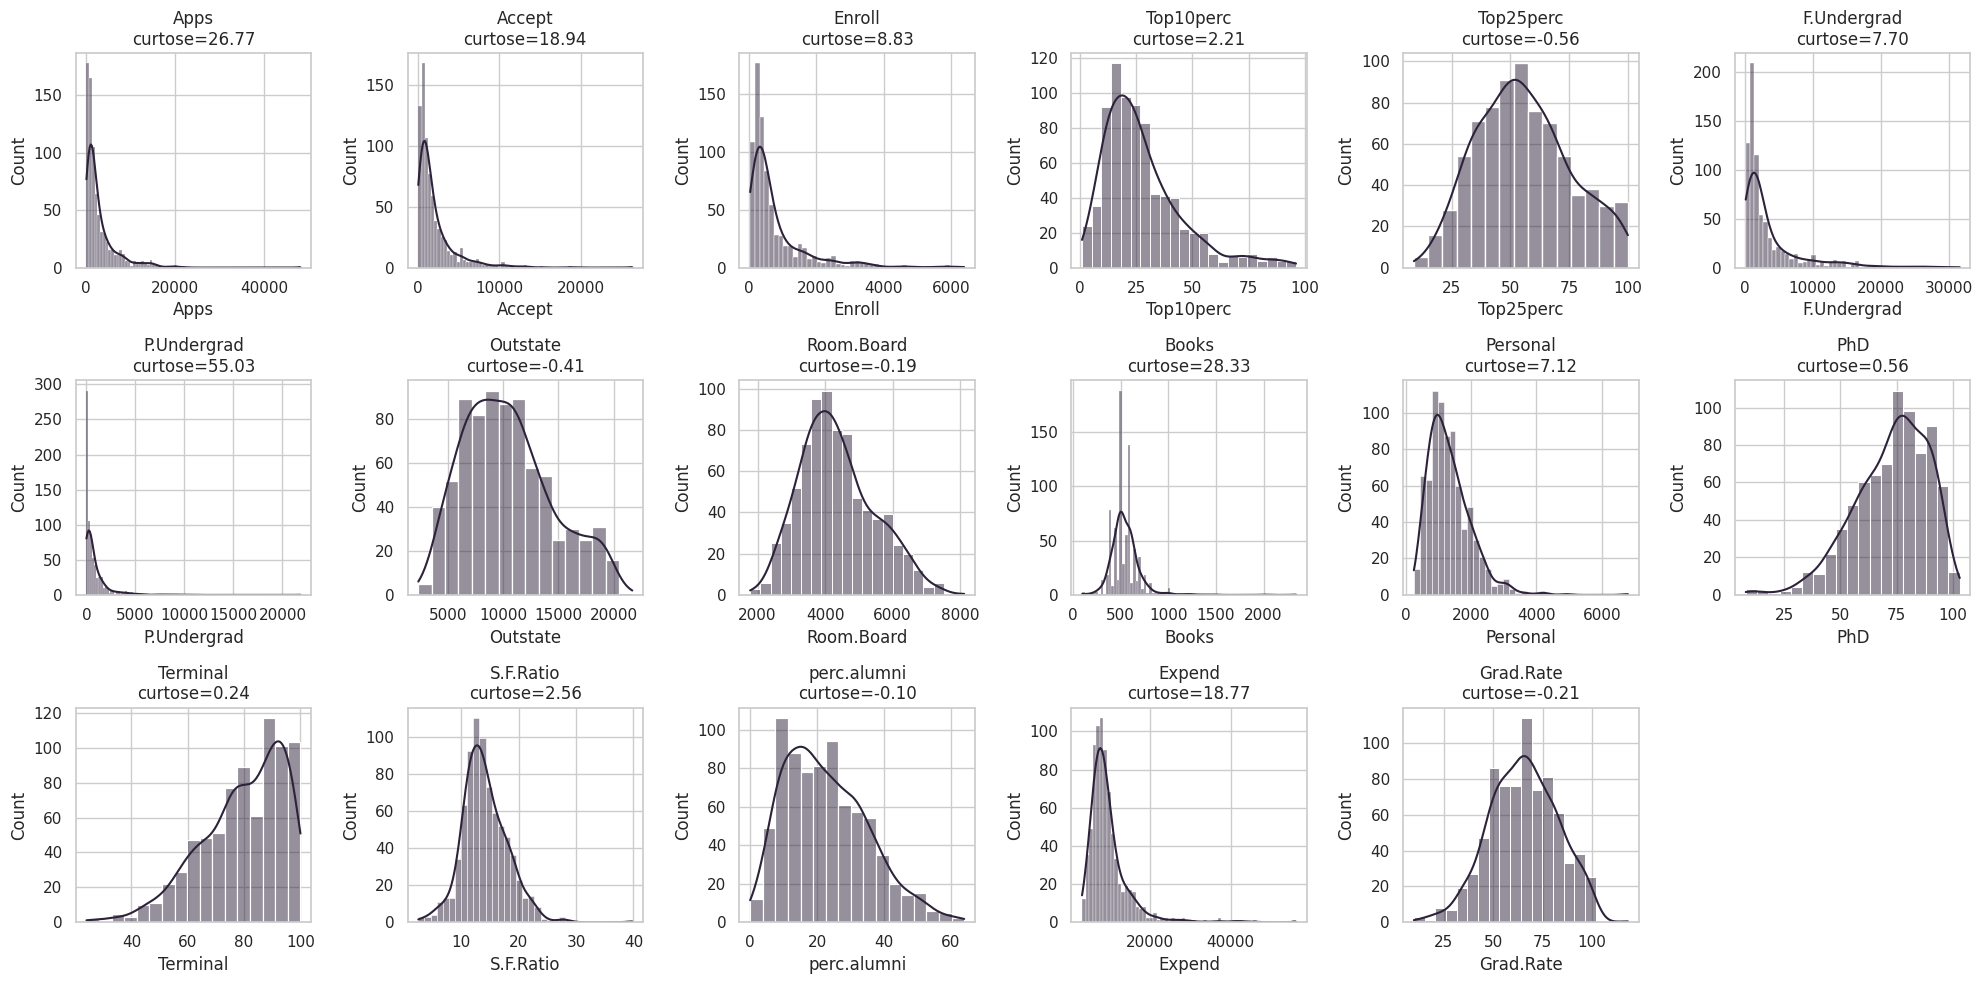

In [104]:
fig, axes = plt.subplots(3, 6, figsize=(20, 10))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(df[col], kde=True, color=COR_DESTAQUE, ax=axes[i])
    k = df[col].kurtosis()
    axes[i].set_title(f"{col}\ncurtose={k:.2f}")

for j in range(len(VARS_QUANT), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

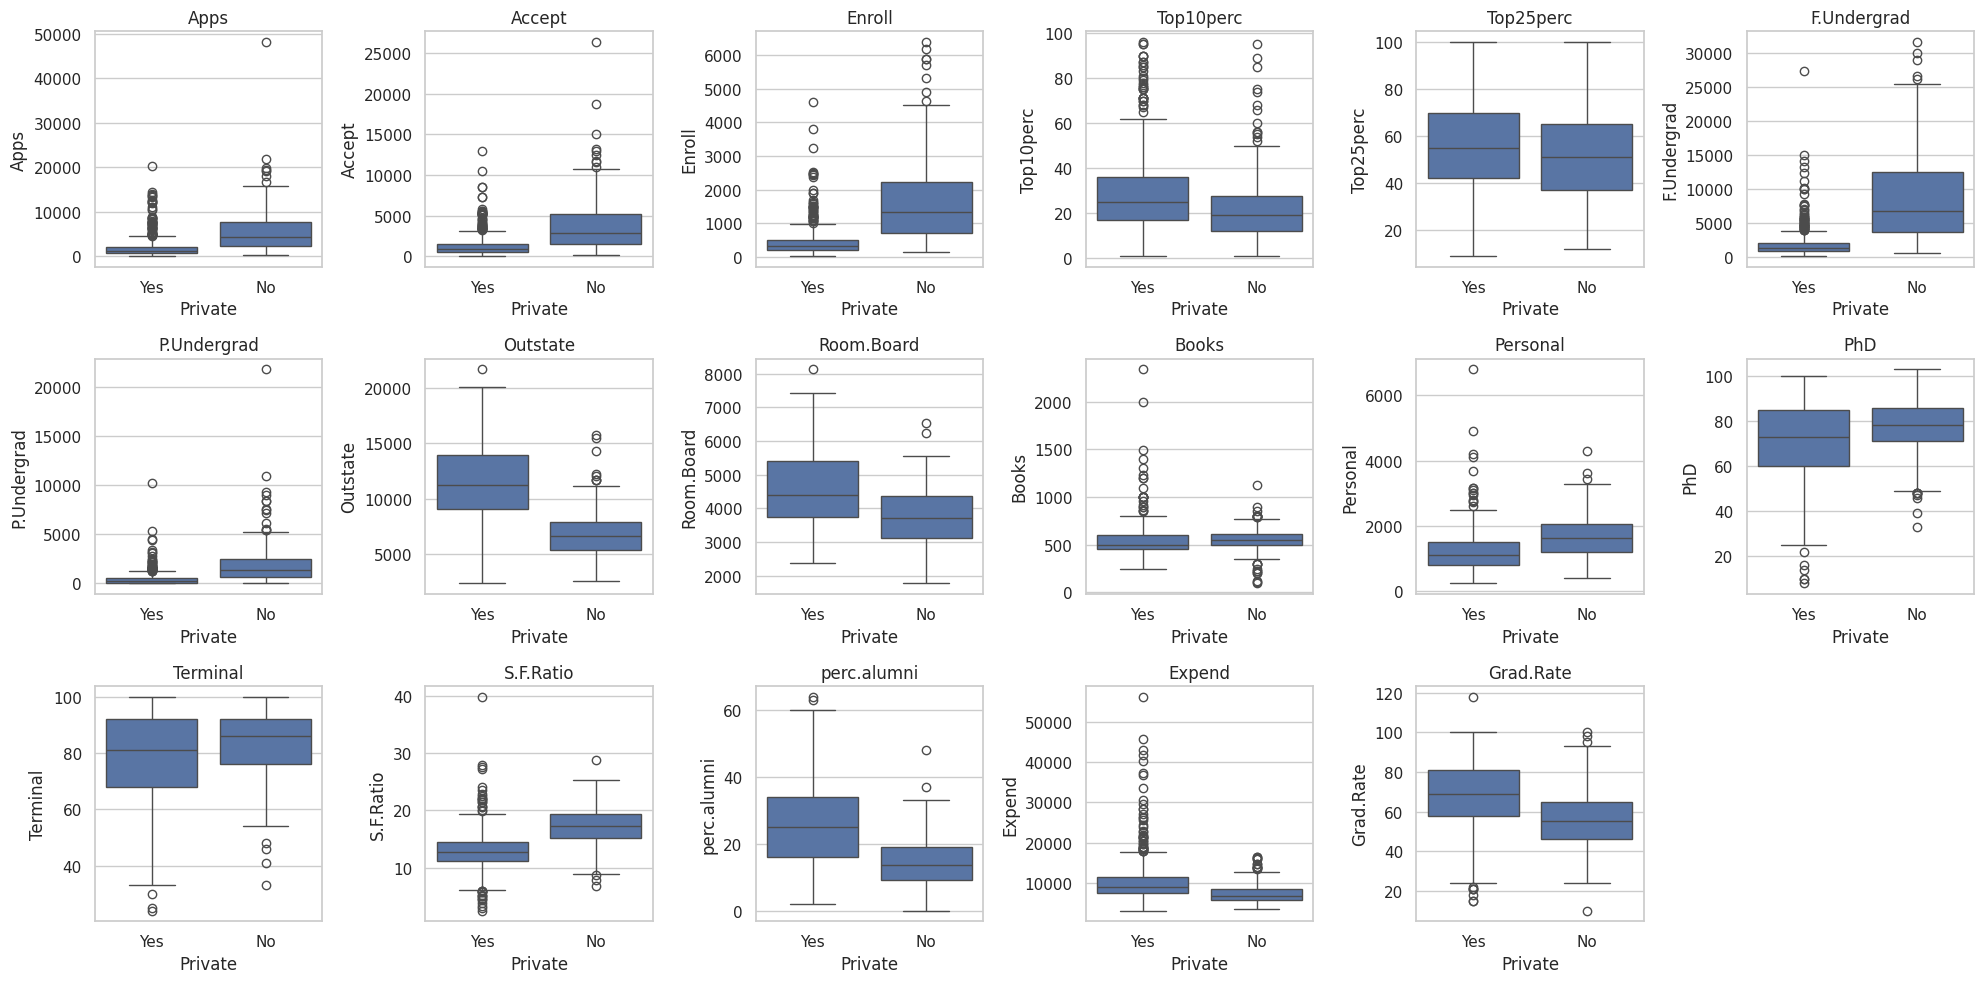

In [105]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 6, figsize=(20, 10))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="Private", y=col, ax=axes[i])
    axes[i].set_title(col)

for j in range(len(VARS_QUANT), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Principais Conclusões da Análise Exploratória de Dados

Com base na Análise Exploratória de Dados (EDA) realizada no dataset `College.csv`, as principais conclusões são:

1.  **Integridade e Distribuição dos Dados:** O dataset apresenta alta integridade, sem valores ausentes ou duplicados. Contudo, a maioria das variáveis quantitativas exibe distribuições altamente assimétricas e com caudas pesadas (curtose elevada), conforme indicado pelos testes de Shapiro-Wilk e visualizações de histogramas e QQ-Plots. Isso sugere que a maioria das instituições possui valores dentro de uma faixa mais comum, mas algumas se destacam com valores extremos.
2.  **Impacto do Status Privado na Distribuição:** O status 'Private' (Instituição Privada/Não Privada) é um fator discriminante significativo para quase todas as variáveis quantitativas. Instituições privadas tendem a apresentar padrões distintos em `Apps`, `Accept`, `Enroll`, `Expend`, `Outstate` e `Grad.Rate` em comparação com as não privadas, conforme evidenciado pelos boxplots, violin plots, e testes de hipóteses (Mann-Whitney U e Kruskal-Wallis).
3.  **Associação Forte entre `Private` e `Apps`:** Há uma associação estatisticamente significativa entre o status `Private` e o número de `Apps` (aplicativos recebidos), mesmo após categorizar `Apps`. Instituições privadas tendem a receber mais aplicativos em faixas 'Baixa' e 'Média', enquanto instituições não privadas concentram-se mais na faixa 'Alta' de aplicativos, conforme o heatmap da contingência e o p-valor do teste Qui-quadrado.
4.  **Correlações Elevadas entre Métricas de Alunos e Finanças:** Observa-se uma alta correlação (Spearman) entre variáveis relacionadas ao número de alunos (`Apps`, `Accept`, `Enroll`, `F.Undergrad`, `P.Undergrad`) e métricas financeiras (`Expend`). Isso indica que a demanda e o porte da instituição estão intrinsecamente ligados aos seus gastos, sugerindo que uma maior captação de alunos pode impulsionar um aumento nos investimentos por aluno.
5.  **Outliers e Tratamento Conservador:** Diversas variáveis quantitativas contêm outliers significativos, que foram considerados estatisticamente raros, mas plausíveis, dentro do contexto educacional. Optou-se por um tratamento conservador de *manutenção* desses outliers, evitando a remoção para preservar informações potencialmente relevantes sobre instituições de perfil atípico.

## Declaração de Uso de Inteligência Artificial (IA)

Durante o processo de Análise Exploratória de Dados (EDA) deste notebook, o assistente de IA **Colab AI / Gemini** foi utilizado como ferramenta de apoio e produtividade. O objetivo principal foi acelerar a adaptação e implementação das técnicas de EDA discutidas em aula para o dataset `College.csv`, além de auxiliar na estruturação do entregável.

### Aplicações da IA:

1.  **Adaptação de Código:** A IA foi extensivamente utilizada para converter e adaptar snippets de código originalmente desenvolvidos para o dataset 'Heart Disease' para o contexto do `College.csv`. Isso incluiu a substituição de nomes de variáveis, ajuste de lógicas e manipulação de tipos de dados.
2.  **Geração de Código:** Foram gerados blocos de código para a realização de diversas etapas da EDA, como cálculo de estatísticas descritivas (assimetria, curtose), visualizações (histogramas, boxplots, violin plots, heatmaps, jointplots, ECDFs), testes de aderência (Shapiro-Wilk) e testes de comparação de grupos (Mann-Whitney U, Kruskal-Wallis, Qui-quadrado).
3.  **Geração de Texto e Discussão:** A IA auxiliou na elaboração de textos explicativos para os resultados das análises, discussões sobre as implicações dos dados (por exemplo, interpretação de p-valores, relevância de outliers), e na construção das seções de 'Principais Conclusões' e 'Documentação do Entregável Final'.
4.  **Resolução de Erros e Sugestões:** A ferramenta ajudou na identificação e correção de `KeyError` e `ValueError` que surgiram devido a inconsistências entre os nomes das colunas dos datasets original e adaptado.

### Sugestões Aceitas, Modificadas e Rejeitadas:

*   **Aceitas:** A maioria das sugestões de código para adaptação de variáveis e geração de visualizações foi aceita integralmente, pois se mostraram eficientes e corretas para a tarefa. As propostas de estrutura e conteúdo para as seções de texto (como esta e as 'Principais Conclusões') também foram amplamente aceitas.
*   **Modificadas:** Algumas sugestões foram modificadas para garantir a correta aplicação das convenções de cores (`COR_NEUTRA`, `COR_CONTEXTO`, `COR_DESTAQUE`) e para refinar a interpretação de resultados estatísticos à luz do conhecimento específico do `College.csv` (e.g., justificar a manutenção de outliers). Em alguns casos, a linguagem gerada foi ajustada para melhor clareza e concisão.
*   **Rejeitadas:** Não houve rejeições totais de sugestões significativas, mas houve omissões deliberadas de certas análises (como a execução de testes bivariados específicos como Pearson e T-Test onde a não-normalidade dos dados recomendava Spearman e Mann-Whitney, respectivamente) conforme a instrução prévia do professor e a própria análise da distribuição dos dados.

## Justificativa das Decisões de EDA e Escolhas

Durante a Análise Exploratória de Dados (EDA) no dataset `College.csv`, diversas decisões foram tomadas em relação ao tratamento dos dados e à escolha das técnicas de análise. Estas decisões foram baseadas nos princípios da EDA, nas características intrínsecas do `College.csv`, e nas instruções do entregável.

### 1. Variáveis Renomeadas/Excluídas (Não Executado)

*   **Contexto Original:** O material didático da aula, baseado no dataset 'Heart Disease', incluía uma etapa de renomear a variável alvo `num` para `doenca_cardiaca` e convertê-la para um formato binário (0 ou 1).
*   **Decisão e Justificativa para `College.csv`:** Para o `College.csv`, essa etapa **não foi executada** porque a variável `Private` já se encaixa perfeitamente como uma variável qualitativa binária ('Yes'/'No'), servindo como nosso atributo alvo principal. Não houve necessidade de renomear ou transformar a variável `Private`, pois ela já estava no formato ideal para as análises subsequentes.

### 2. Tratamento de Dados Ausentes (Não Executado)

*   **Contexto Original:** O material didático previa a discussão e tratamento de dados ausentes nas variáveis `ca` e `thal` do dataset 'Heart Disease', incluindo a análise do mecanismo de ausência (MCAR/MAR/MNAR) e a remoção de linhas afetadas.
*   **Decisão e Justificativa para `College.csv`:** A etapa de tratamento de dados ausentes **não resultou em nenhuma modificação** para o `College.csv`. A execução da célula `df.isna().sum()` (célula `9W6XRthX0JgY`) demonstrou que o dataset `College.csv` não possui nenhum valor ausente em nenhuma de suas colunas. Portanto, as discussões teóricas sobre mecanismos de ausência e as células de remoção (`pDGY6EOZK-K_`) foram mantidas no notebook para fins didáticos e de contextualização com a aula, mas não tiveram impacto prático no dataset atual, pois não havia dados para serem tratados.

### 3. Tratamento de Outliers (Decisão de Manter)

*   **Contexto Original:** Foram apresentadas técnicas para detecção de outliers (regra do IQR) e uma matriz de decisão sobre como tratá-los (manter, transformar, investigar, corrigir/remover).
*   **Decisão e Justificativa para `College.csv`:** Após a detecção de outliers em diversas variáveis quantitativas (célula `1LCYAbOCJ_51` e `kr1o4eL6KgbH`), a decisão foi por **manter** esses valores. A justificativa reside no fato de que os outliers observados (por exemplo, em `Apps`, `Accept`, `Enroll`, `Expend`) são considerados **outliers estatísticos legítimos** dentro do domínio do contexto educacional. São valores atípicos que representam instituições reais com características incomuns (ex: universidades com um número extremamente alto de candidatos ou gastos elevados), e não erros de digitação ou violações de regras de negócio. A remoção indiscriminada desses pontos poderia levar à perda de informações valiosas sobre a diversidade das instituições. Embora a transformação logarítmica tenha sido ilustrada com `Expend_log` (célula `Y3pKg9I8LZye`) para demonstrar como reduzir a assimetria, optou-se por não aplicá-la em todo o dataset para as análises exploratórias, preservando a interpretabilidade dos dados em sua escala original.

### 4. Escolha de Testes Estatísticos para Análise Bivariada (Preferência por Não-Paramétricos)

*   **Contexto Original:** A aula abordou testes paramétricos (T-Test, ANOVA) e não-paramétricos (Mann-Whitney U, Kruskal-Wallis) para comparação de grupos, destacando a importância da premissa de normalidade para os testes paramétricos.
*   **Decisão e Justificativa:** A análise de aderência à normalidade via teste de Shapiro-Wilk (célula `3iqxE7SEFcF7`) revelou que **todas** as variáveis quantitativas do `College.csv` rejeitam a hipótese de normalidade (p-valor < 0.05). Diante disso:
    *   Para a análise de correlação entre variáveis quantitativas, o **coeficiente de Spearman** (e Kendall) foi priorizado sobre o Pearson (célula `37We_0E-TX-6`), pois Spearman é mais robusto a distribuições não-normais e a relações não-lineares, mas monotônicas.
    *   Para a comparação de variáveis quantitativas entre os dois grupos da variável `Private`, os testes **Mann-Whitney U** (para dois grupos) e **Kruskal-Wallis** (para 3+ grupos, caso houvesse) foram considerados os mais apropriados e seus resultados foram priorizados sobre os resultados do T-Test e ANOVA, respectivamente (células `1Im2nrG9V0xh` e `BQAbrVtHWLoe`). Embora os testes paramétricos tenham sido calculados para fins de comparação e ilustração, a falta de normalidade no `College.csv` torna os testes não-paramétricos mais confiáveis para inferência.

### 5. Categorização da Variável `Apps` (Geração de `Apps_binned`)

*   **Contexto:** Para facilitar a análise de associação entre uma variável quantitativa (`Apps`) e a qualitativa (`Private`) por meio de um teste Qui-quadrado, foi necessário categorizar `Apps`.
*   **Decisão e Justificativa:** A variável `Apps_binned` foi criada (célula `crYi1UlRWdNq`) utilizando `pd.qcut` para dividir o número de aplicativos em três categorias ('Baixo', 'Médio', 'Alto') com base nos quantis. Esta categorização permitiu aplicar o teste Qui-quadrado para verificar a independência entre `Private` e as faixas de `Apps`, além de visualizar a distribuição dessas categorias por meio de um mapa de calor e barras empilhadas, enriquecendo a análise relacional.

### 6. Avaliação de Fairness (Uso de `Private` e `Apps_binned`)

*   **Contexto:** A análise de fairness busca verificar se a distribuição de um desfecho (`Apps_binned`) varia entre subgrupos de um atributo sensível (`Private`).
*   **Decisão e Justificativa:** A avaliação de fairness foi realizada (células `BY6ykKTWYMMp` e `c_n2zIj6YR6g`) utilizando `Private` como o atributo sensível e `Apps_binned` como o desfecho. Isso permitiu investigar se a proporção de instituições em cada faixa de aplicativos ('Baixo', 'Médio', 'Alto') difere significativamente entre instituições privadas e não privadas. Essa análise é crucial para identificar possíveis vieses ou padrões que possam impactar a percepção ou a realidade de acesso e demanda das instituições, mesmo em um contexto não diretamente relacionado à saúde.